In [6]:
import cv2 as cv2
import numpy as np
from scipy import ndimage
from matplotlib import pyplot as plt

[[130 121 112 ... 188 188 186]
 [193 193 189 ... 186 185 189]
 [229 230 231 ... 190 186 183]
 ...
 [215 223 229 ... 217 222 222]
 [216 223 228 ... 217 221 223]
 [216 223 228 ... 217 221 223]]


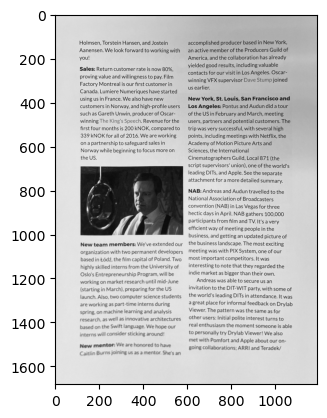

In [13]:
image = cv2.imread('ouputito.jpeg')
img = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
img_h, img_w = image.shape[:2]
print(img)

plt.imshow(img, cmap='gray')

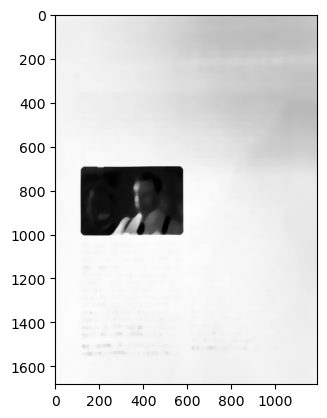

In [14]:
median_filter = ndimage.median_filter(img, size=30)

plt.imshow(median_filter, cmap='gray')

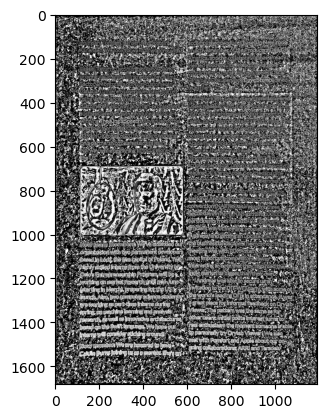

In [15]:
filtered = img - median_filter

plt.imshow(filtered, cmap='gray')

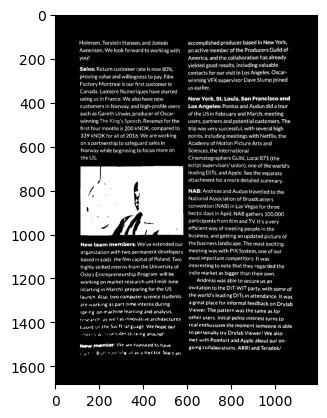

In [16]:
binary = img > 150

binary = np.abs(binary -1)

plt.imshow(binary, cmap='gray')
plt.imsave('dilatation.jpeg', binary, cmap='gray')

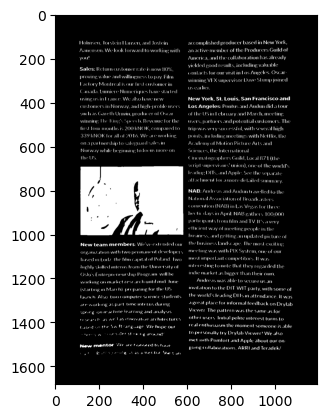

In [17]:
kernel_horitzontal = np.array([[1], [1], [1]])
prueba1 = ndimage.binary_erosion(binary, kernel_horitzontal, iterations=1)

plt.imshow(prueba1, cmap='gray')
plt.imsave('dilatation.jpeg', prueba1, cmap='gray')

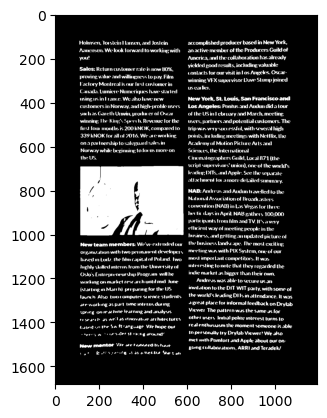

In [18]:

kernel_vertical = np.array([[1, 0,  0] , [1, 1, 1], [1 , 0, 0]])
prueba2 = ndimage.binary_dilation(prueba1,kernel_vertical , iterations=1)
plt.imsave('dilatation.jpeg', prueba2, cmap='gray')
plt.imshow(prueba2, cmap='gray')

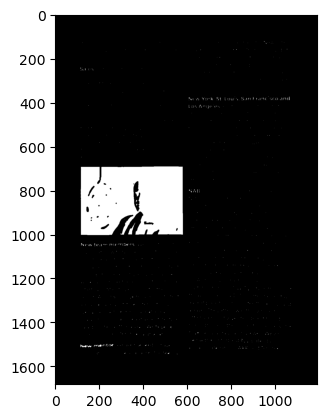

In [19]:
eroded = ndimage.binary_erosion(binary, iterations=2)

plt.imshow(eroded, cmap='gray')

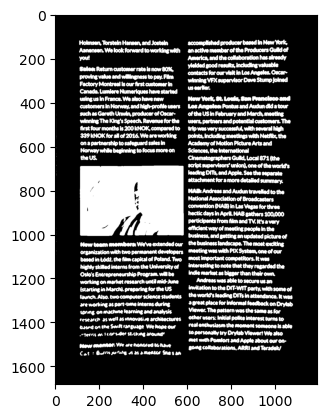

In [20]:
dilatation_cont = ndimage.binary_dilation(binary, iterations=1)
dilatation = ndimage.binary_dilation(dilatation_cont, iterations=1)
plt.imsave('dilatation.jpeg', dilatation_cont, cmap='gray')
plt.imshow(dilatation, cmap='gray')

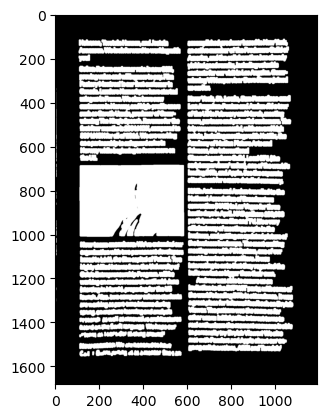

In [21]:
kernel5 = np.array([[1], [1], [1], [1], [1]]) 
filtered_image = dilatation.astype(np.uint8)
dilated_image = cv2.dilate(filtered_image, kernel5, iterations=2)

kernel2 = np.array([[1], [1]])
dilated_image_2 = cv2.dilate(dilated_image, kernel2, iterations=2)

kernel_horitzontal = kernel2 = np.array([[1, 1, 1]])
dilated = cv2.dilate(dilated_image, kernel_horitzontal, iterations=2)



plt.imshow(dilated, cmap='gray')
plt.imsave('characters.jpeg', dilated, cmap='gray')

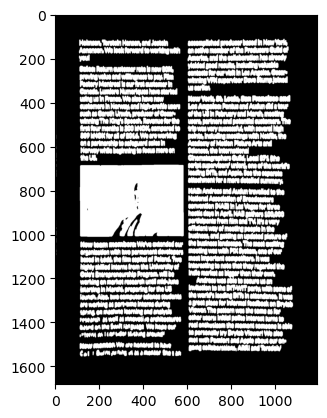

In [22]:
binary_for_contours = dilated * 255
binary_for_contours = binary_for_contours.astype(np.uint8)

contours, hierarchy = cv2.findContours(binary_for_contours, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

plt.imshow(dilated_image, cmap='gray')
#plt.imsave('characters.jpeg', binary_for_contours, cmap='gray')
output_image_bounding_boxes = image.copy() # Nueva imagen para dibujar bounding boxes


In [23]:
output_image_hulls = image.copy()
output_image_contours_hulls = image.copy() # Para dibujar contornos y hulls
hull_coordinates_list = [] # Lista para almacenar las coordenadas (x1, y1, x2, y2)
output_image_bounding_boxes_filtered = image.copy()

for i, cnt in enumerate(contours):
    # convexHull necesita al menos 3 puntos.boundingRect también se beneficia de esto.

    hull = cv2.convexHull(cnt)

    # Dibujar el contorno de la envoltura convexa (opcional)
    cv2.drawContours(output_image_hulls, [hull], -1, (0, 255, 0), 2)

    # Dibujar el "bloque" relleno de la envoltura convexa (opcional)
    cv2.drawContours(output_image_contours_hulls, [hull], -1, (0, 255, 0), cv2.FILLED)

    # --- Calcular y almacenar las coordenadas del Bounding Box del HULL ---
    # x_rect, y_rect son las coordenadas de la esquina superior izquierda del rectángulo
    # w_rect, h_rect son el ancho y la altura
    x_rect, y_rect, w_rect, h_rect = cv2.boundingRect(hull)

    # Definir x1, y1, x2, y2 según tu especificación (estándar para bounding box)
    x1 = x_rect
    y1 = y_rect
    x2 = x_rect + w_rect
    y2 = y_rect + h_rect

    hull_coordinates_list.append({
        "id": f"hull_{i}",
        "hull_points": hull, # Guardamos los puntos del hull
        "x1": x_rect,
        "y1": y_rect,
        "x2": x_rect + w_rect,
        "y2": y_rect + h_rect,
        "w": w_rect,
        "h": h_rect,
        "area": w_rect * h_rect
    })



In [24]:
filtered_hull_coordinates_list = []
last_x1 = x1
last_y1 = y1
last_x2 = x2
last_y2 = y2

x_tolerance = 3
bbox2 = []

for hull_info in hull_coordinates_list:
    w = hull_info["w"]
    h = hull_info["h"]
    area = hull_info["area"]
    x1 = fx1 = hull_info["x1"]
    y1 = fy1 = hull_info["y1"]
    x2 = fx2 = hull_info["x2"]
    y2 = fy2 = hull_info["y2"]

    aspect_ratio = float('inf')
    if h > 0:
        aspect_ratio = w / h

    is_marginal = (x1 < 15 or
                   y1 < 15 or
                   x2 > (img_w - 15) or
                   y2 > (img_h - 15))

    is_last = 1 #(x2 - last_x1 < x_tolerance or abs(y2 - last_y1) < x_tolerance)

    
    if not is_marginal:
             if is_last == 1:
                
                bbox_binary = dilatation[fy1:fy2, fx1:fx2]
                bbox = bbox_binary.astype(np.uint8) * 255
                bbox2.append(bbox)

                contours, _ = cv2.findContours(bbox, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
                len_contours = len(contours)
                filtered_hull_coordinates_list.append({
                    "label": hull_info['id'],
                    "x1": x1, "y1": y1, "x2": x2, "y2": y2, "len_contours": len_contours
                    })
                cv2.rectangle(output_image_bounding_boxes_filtered, (fx1, fy1), (fx2, fy2), (0, 0, 255), 1)
             else:
                  filtered_hull_coordinates_list.pop()
                  fx1 = min(last_x1, x1)
                  fy1 = min(last_y1, y1)
                  fx2 = max(last_x2, x2)
                  fy2 = max(last_y2, y2)
                  filtered_hull_coordinates_list.append({
                    "label": hull_info['id'],
                    "x1": fx1, "y1": fy1, "x2": fx2, "y2": fy2
                    })

    
    

    last_x1 = x1
    last_y1 = y1
    last_x2 = x2
    last_y2 = y2

In [25]:
for item in filtered_hull_coordinates_list:
    print(f"  {item['label']}: x1={item['x1']}, y1={item['y1']}, x2={item['x2']}, y2={item['y2']}, len_contours={item['len_contours']}")

  hull_0: x1=169, y1=1533, x2=179, y2=1552, len_contours=2
  hull_1: x1=545, y1=1531, x2=576, y2=1555, len_contours=1
  hull_2: x1=111, y1=1529, x2=158, y2=1557, len_contours=3
  hull_3: x1=358, y1=1528, x2=384, y2=1553, len_contours=1
  hull_4: x1=332, y1=1528, x2=357, y2=1552, len_contours=1
  hull_5: x1=385, y1=1527, x2=484, y2=1553, len_contours=2
  hull_6: x1=185, y1=1526, x2=329, y2=1555, len_contours=5
  hull_7: x1=487, y1=1524, x2=544, y2=1555, len_contours=2
  hull_8: x1=606, y1=1501, x2=1032, y2=1534, len_contours=5
  hull_9: x1=318, y1=1492, x2=531, y2=1520, len_contours=6
  hull_10: x1=110, y1=1490, x2=317, y2=1523, len_contours=4
  hull_11: x1=606, y1=1467, x2=1055, y2=1502, len_contours=8
  hull_12: x1=192, y1=1447, x2=220, y2=1469, len_contours=1
  hull_13: x1=110, y1=1447, x2=189, y2=1471, len_contours=7
  hull_14: x1=414, y1=1442, x2=501, y2=1469, len_contours=1
  hull_15: x1=329, y1=1442, x2=413, y2=1472, len_contours=3
  hull_16: x1=223, y1=1440, x2=327, y2=1467, len

In [ ]:
plt.imsave('hulls.jpeg', output_image_bounding_boxes_filtered, cmap='gray')
plt.imshow(output_image_bounding_boxes_filtered, cmap='gray')

In [ ]:
plt.imshow(bbox2[12], cmap='gray')